### IMPORTS

In [1]:
import os
import json
import numpy as np
from IPython.display import display, Image
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib import colors
import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker

In [2]:
from src_ml_emulator.data_reader import DataReader

### Set Paths

In [3]:
### path to Training/Test Datasets
path_experiment_dataset = '/data/users/adistefano/ml_emulator/download_data/'
### path where to save the model results
path_ml_results = '/data/users/adistefano/ml_emulator/generated'

#### Select Training Experiment 

In [4]:
### list trained models
os.listdir(path_ml_results)

['emulator_20261105',
 'emulator_20251106',
 'emulator_20250527',
 'logs',
 'emulator_20260528',
 'emulator_20260529',
 'emulator_20261026']

In [5]:
# select folder of past experiments from list above
NAME="emulator_20261105"
#
GENERATED_DIR = path_ml_results

# Create rundir
RUNDIR = os.path.join(GENERATED_DIR, NAME)
if(os.path.isdir(RUNDIR)):
    print(f"Found Experiment: {RUNDIR}")
else:
    raise ValueError(f"Experiment {RUNDIR} not found!")

# file with grid
#TOPO_FILE = grid_file
# file with training files (relative) paths
TRAIN_SCENARIOS = os.path.join(RUNDIR, "train_scenarios.csv")
# file with validation files (relative) paths
VALIDATION_SCENARIOS = os.path.join(RUNDIR, "validation.csv")
# file with test files (relative) paths
TEST_SCENARIOS = os.path.join(RUNDIR, "test.csv")
OUT_DIR = os.path.join(RUNDIR,"predictions")
# file to experiment data
TRAIN_DIR = path_experiment_dataset
VALIDATION_DIR = TRAIN_DIR
TEST_DIR = TRAIN_DIR

# Optionally can be set to a specific file from previous run
TOPO_MASK = os.path.join(RUNDIR, "topomask.npy")
GRID_INFO_FILE = os.path.join(RUNDIR, "grid_info.json")

Found Experiment: /data/users/adistefano/ml_emulator/generated/emulator_20261105


### Model Evaluation

##### Training Summary

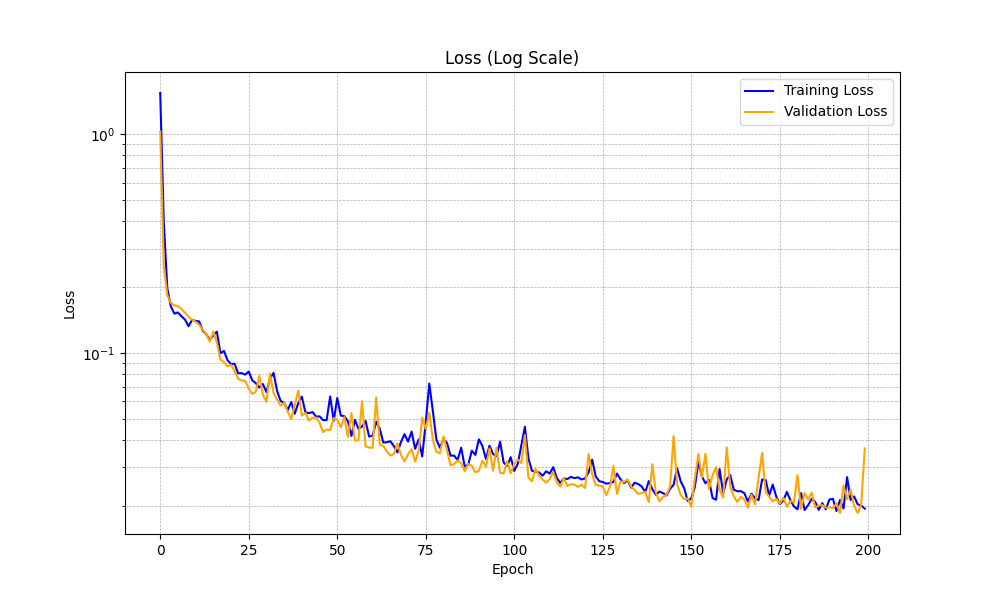

In [6]:
display(Image(f'{RUNDIR}/train_summary_loss.png'))

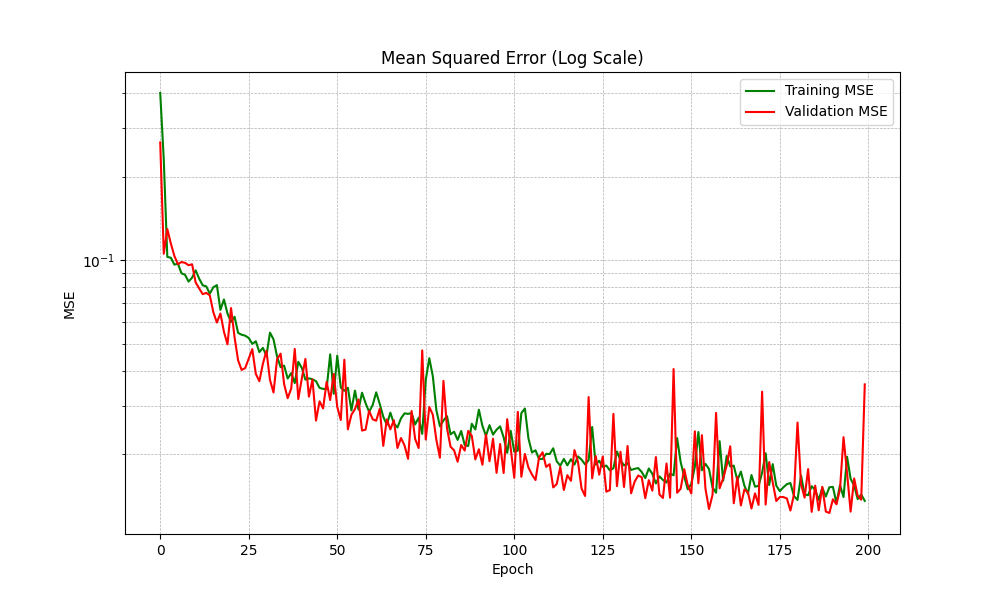

In [7]:
display(Image(f'{RUNDIR}/train_summary_mse.png'))

#### Predicted flowdepth vs Simulated Flow Depth

In [8]:
datareader=DataReader(
                    rundir=RUNDIR,
                    scenarios_file=TEST_SCENARIOS,
                    datadir=TEST_DIR
                    )
topo_mask = datareader.topomask
#
with open(GRID_INFO_FILE) as f:
    grid_info_tmp = json.load(f)
lat = grid_info_tmp['variables']['lat']['data']
lon = grid_info_tmp['variables']['lon']['data']
#
lon2d, lat2d = np.meshgrid(lon, lat)
lon_mask = lon2d[topo_mask]
lat_mask = lat2d[topo_mask]


Processing scenario: E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000/C_CT.nc


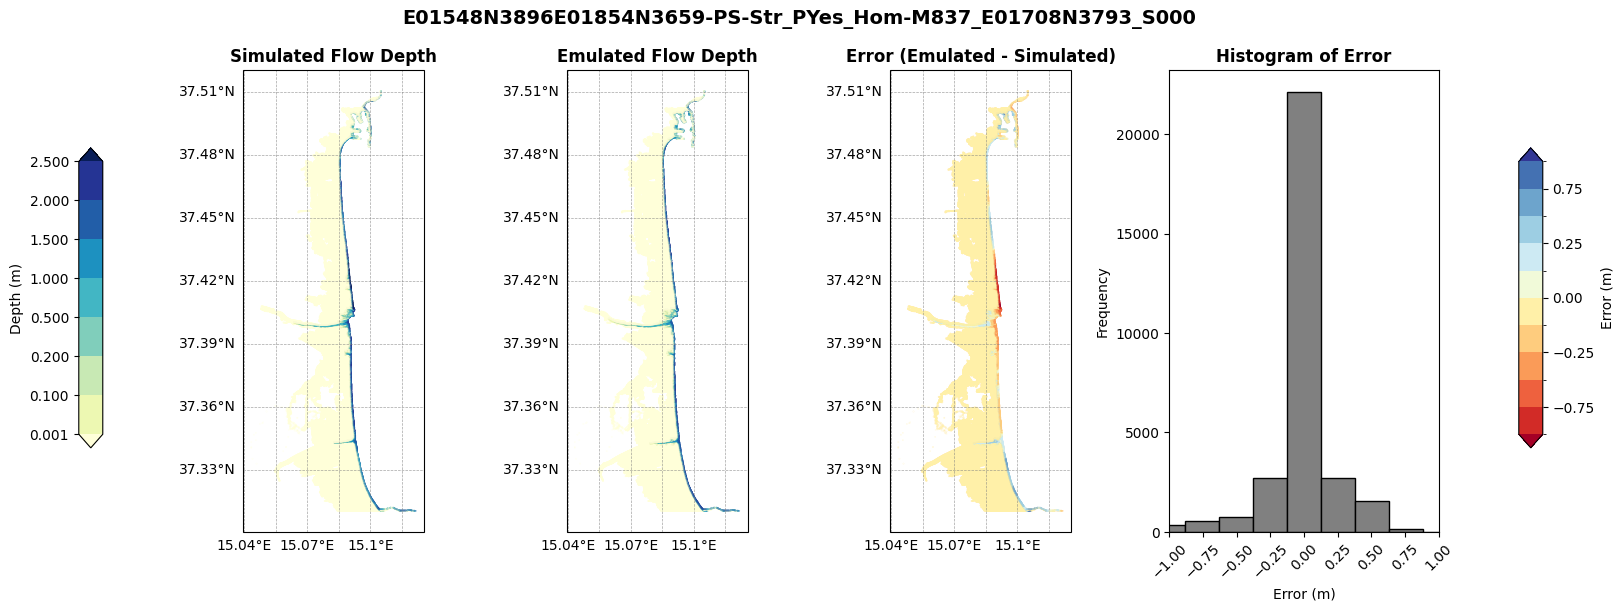

Processing scenario: E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000/C_CT.nc


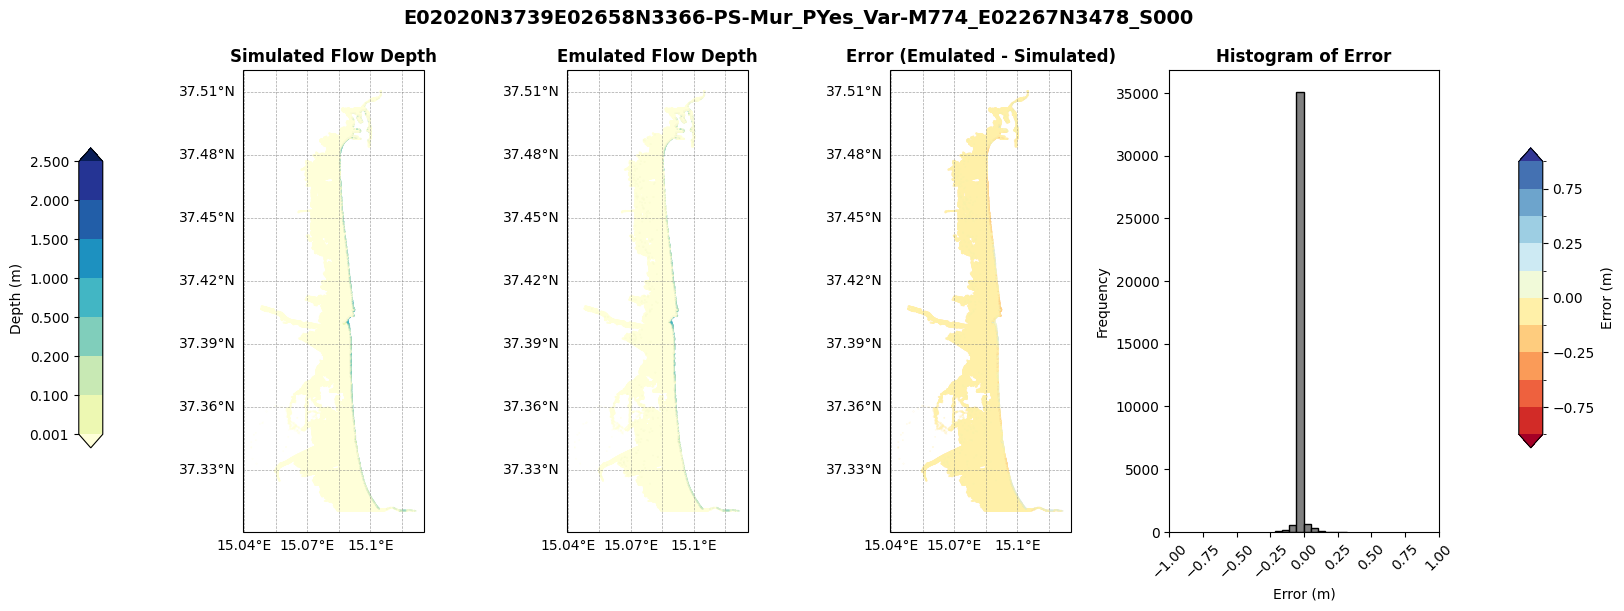

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Hom-M895_E02217N3548_S005
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M895_E02217N3548_S005/C_CT.nc


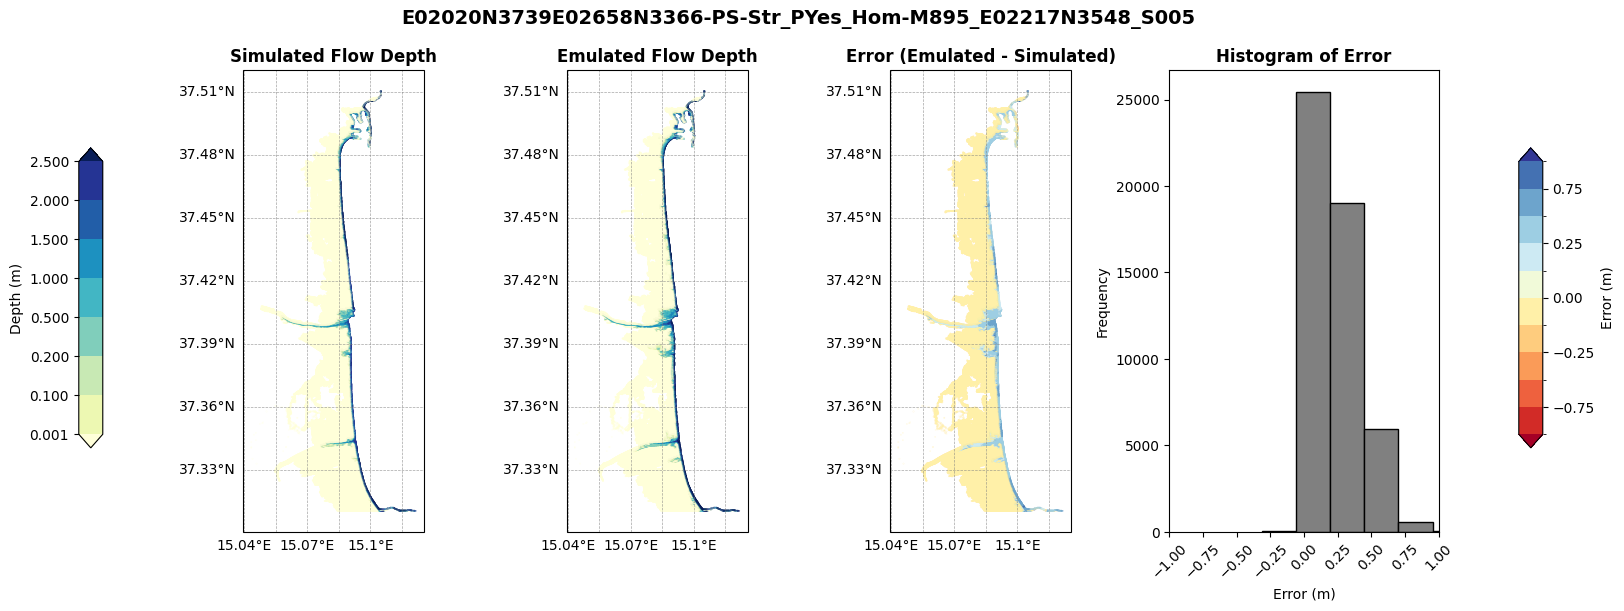

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02218N3525_S003
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02218N3525_S003/C_CT.nc


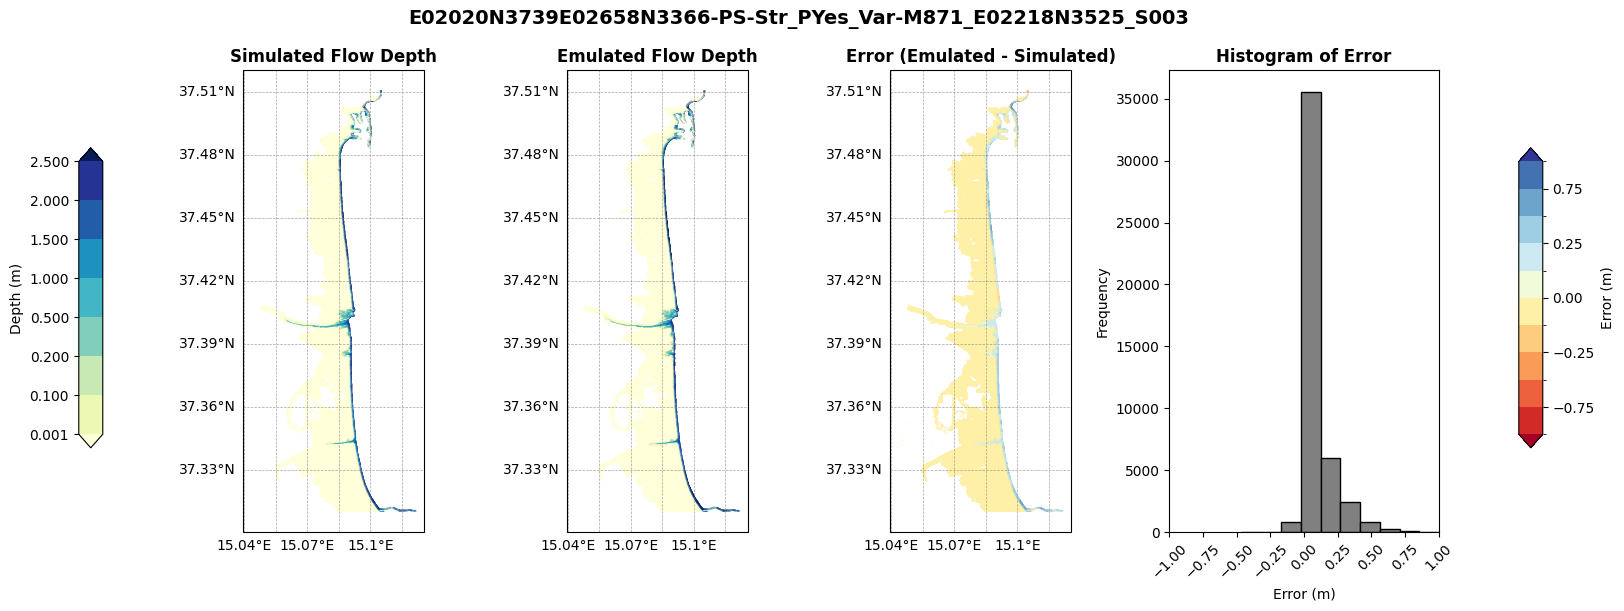

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M902_E02318N3471_S001
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M902_E02318N3471_S001/C_CT.nc


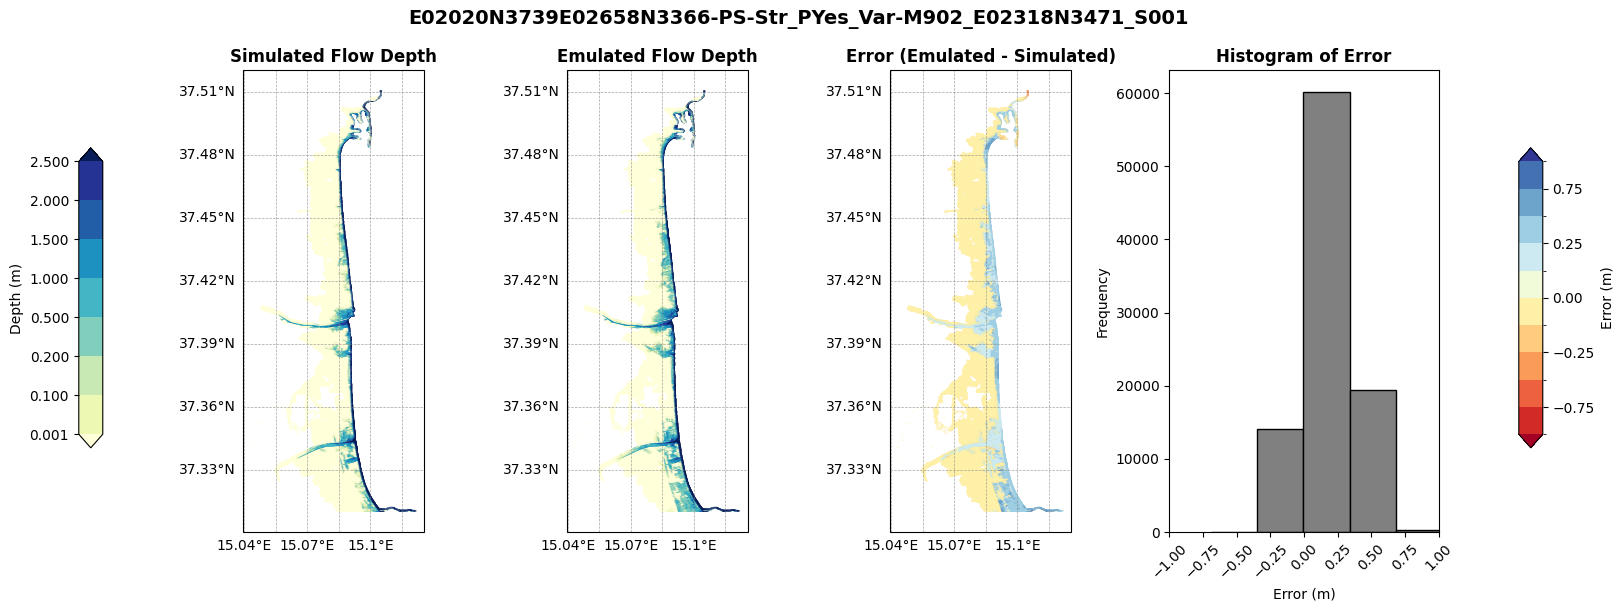

Processing scenario: E01548N3896E01854N3659-PS-Mur_PYes_Var-M792_E01612N3787_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Mur_PYes_Var-M792_E01612N3787_S000/C_CT.nc


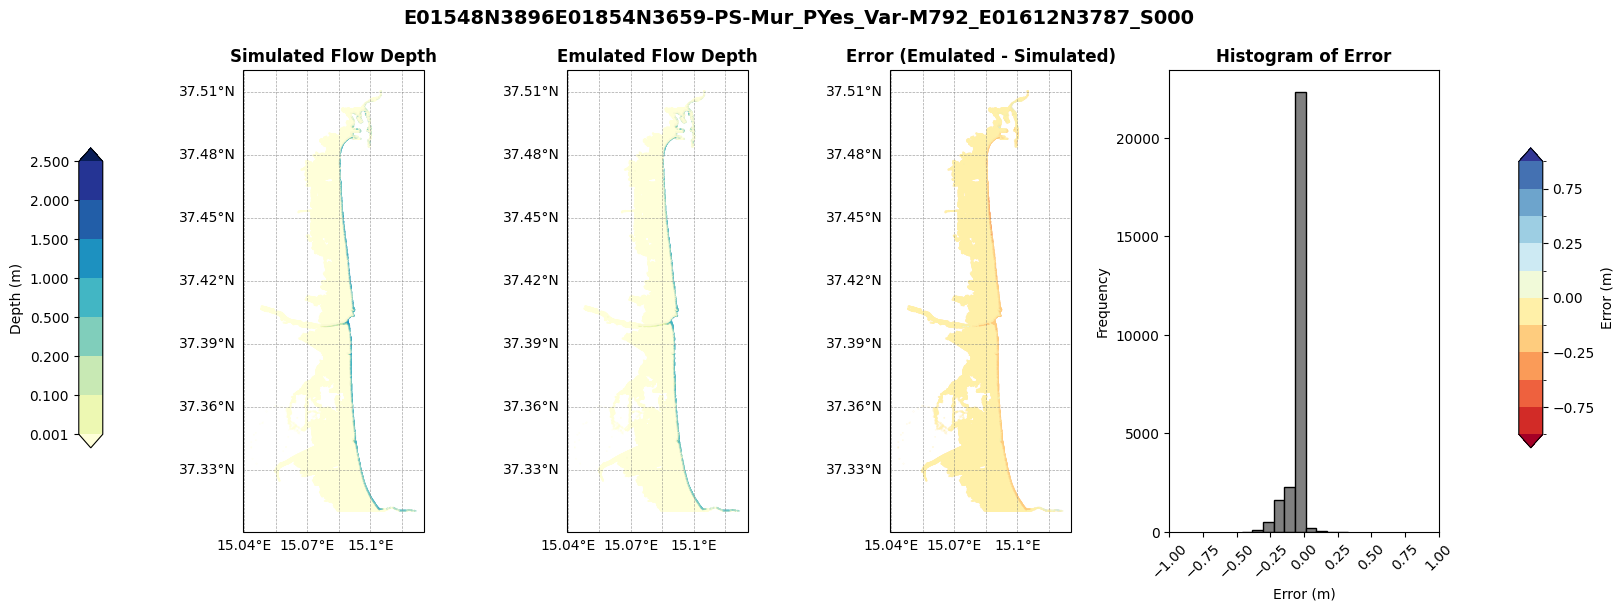

Processing scenario: E01548N3896E01854N3659-PS-Str_PYes_Var-M809_E01699N3763_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Var-M809_E01699N3763_S000/C_CT.nc


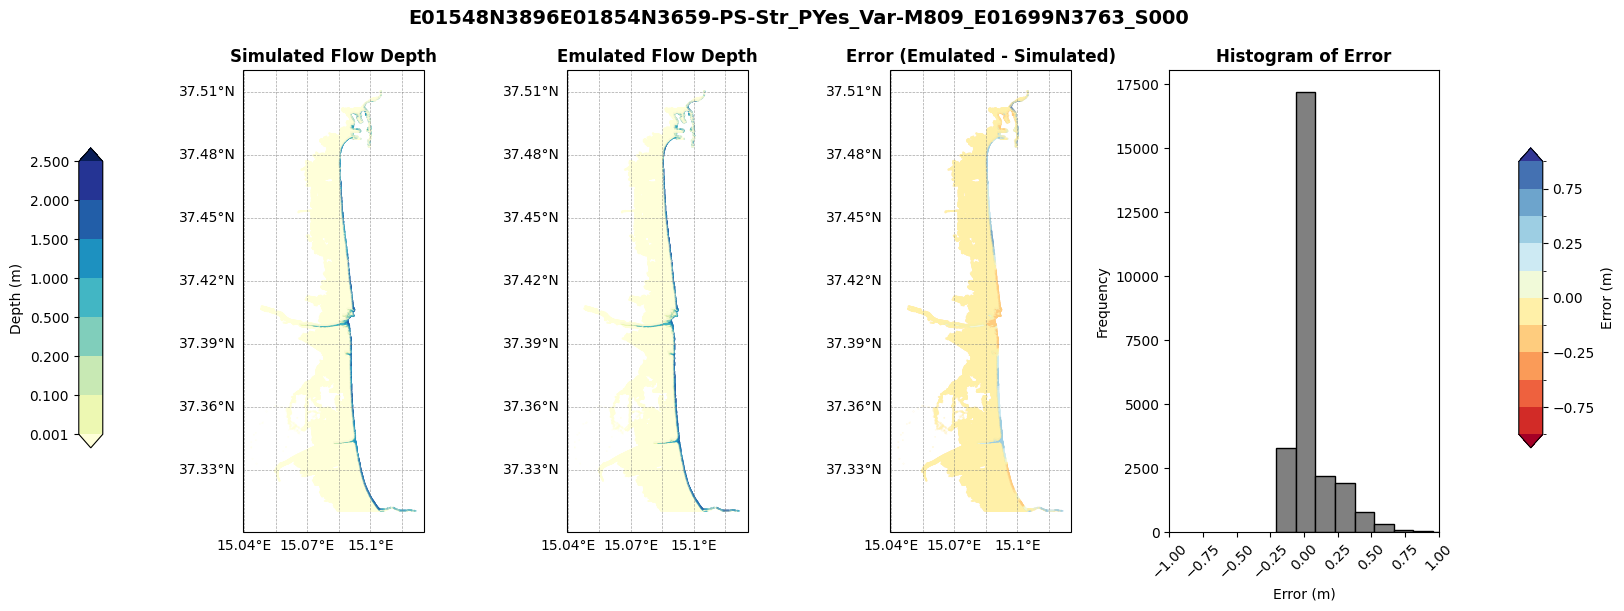

Processing scenario: E02020N3739E02658N3366-PS-Mur_PYes_Var-M861_E02166N3518_S004
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M861_E02166N3518_S004/C_CT.nc


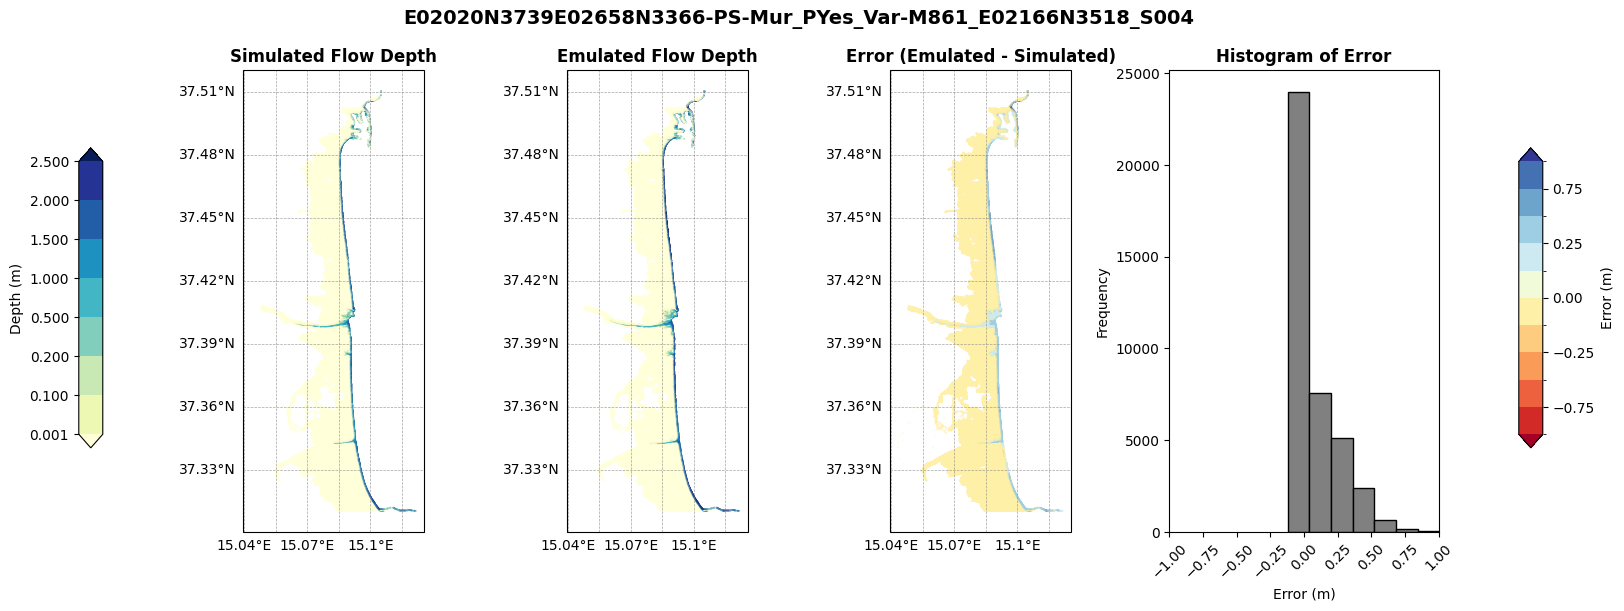

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02401N3479_S005
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02401N3479_S005/C_CT.nc


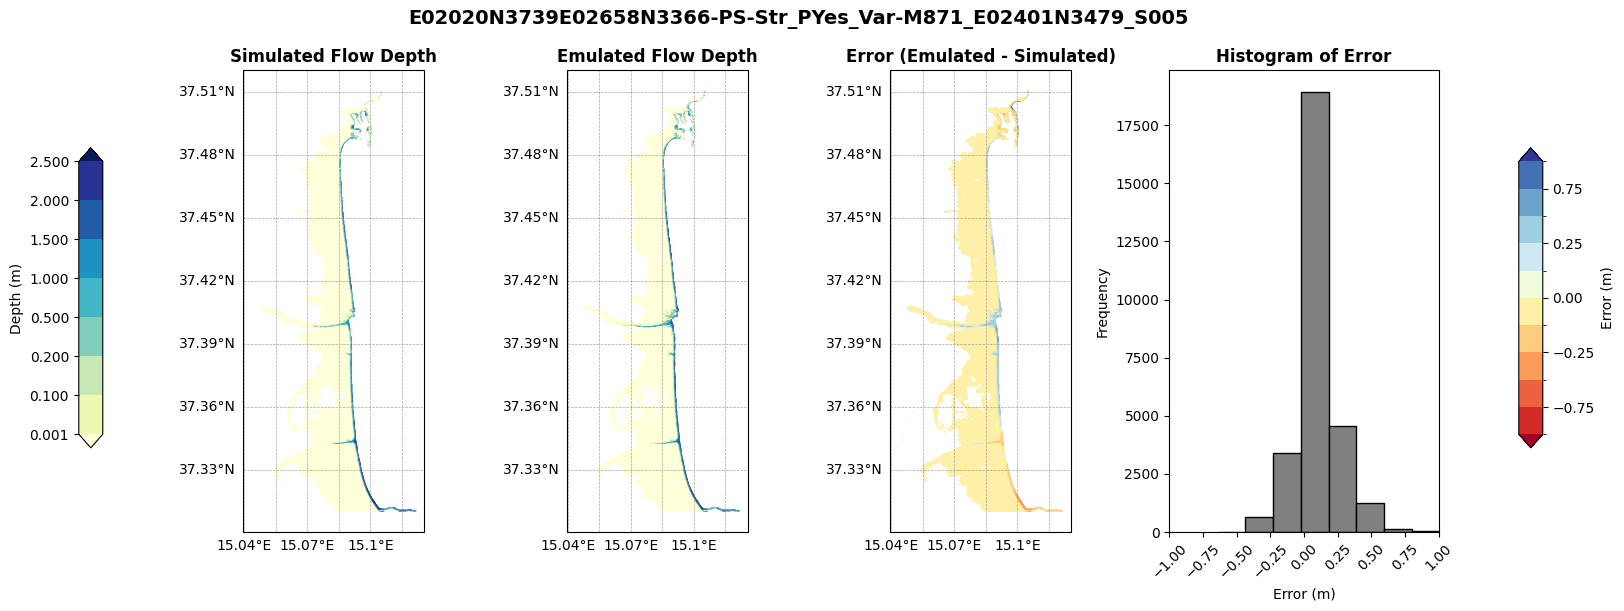

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E02349N3441_S003
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E02349N3441_S003/C_CT.nc


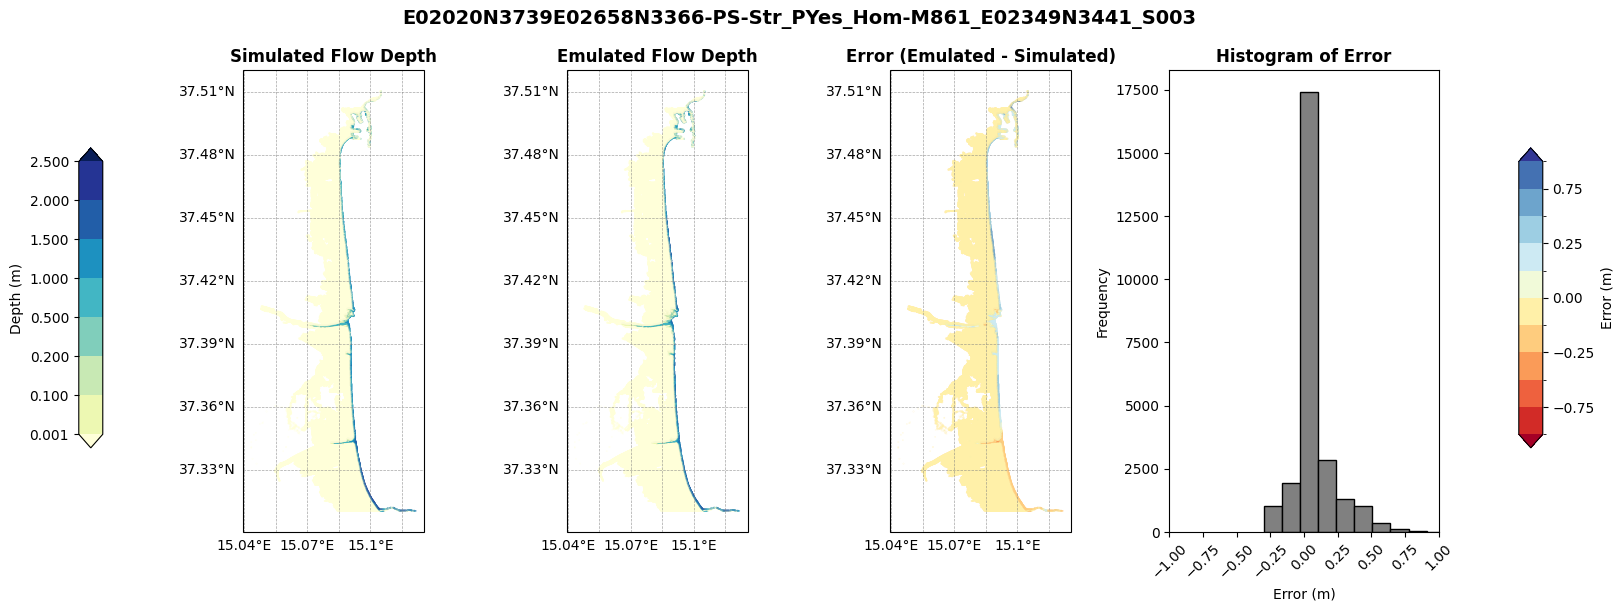

In [9]:
df_test = pd.read_csv(TEST_SCENARIOS,header=None,names=['scenario_name','c_ct','grid0_ts'])
for scenario_name, file_ct in zip(df_test.scenario_name,df_test.c_ct):  # Loop through all scenarios

    # Read the data for the scenario
    print(f"Processing scenario: {scenario_name}")
    print(f"Analyze file {file_ct}")
    simulated_depth,_ = datareader.get_flow_depth(path_file_ct=file_ct,full_path=False)
    emulated_ds = xr.open_dataset(os.path.join(OUT_DIR, f"{scenario_name}_predictions.nc"))
        
    z_sim = simulated_depth
    z_emul = emulated_ds.predicted.values[topo_mask]  # Emulated depth from the prediction
    error = z_emul - z_sim  # Error map

    # Setup figure and subplots
    fig, axs = plt.subplots(1, 4, figsize=(16, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    depth_cmap = colormaps['YlGnBu']
    depth_bounds = [0.001, 0.1, 0.2, 0.5, 1, 1.5, 2, 2.5]
    depth_norm = colors.BoundaryNorm(depth_bounds, depth_cmap.N, extend='both')

    # --- Plot 1: Simulated ---
    sc0 = axs[0].scatter(lon_mask, lat_mask, c=z_sim, cmap=depth_cmap, norm=depth_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[0].set_title("Simulated Flow Depth", fontsize=12, fontweight="bold")
    gl0 = axs[0].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl0.top_labels = gl0.right_labels = False
    gl0.xformatter = cticker.LongitudeFormatter()
    gl0.yformatter = cticker.LatitudeFormatter()

    # --- Plot 2: Emulated ---
    sc1 = axs[1].scatter(lon_mask, lat_mask, c=z_emul, cmap=depth_cmap, norm=depth_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[1].set_title("Emulated Flow Depth", fontsize=12, fontweight="bold")
    gl1 = axs[1].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl1.top_labels = gl1.right_labels = False
    gl1.xformatter = cticker.LongitudeFormatter()
    gl1.yformatter = cticker.LatitudeFormatter()

    # --- Plot 3: Error Map ---
    error_cmap = colormaps['RdYlBu']
    error_bounds = [-1, -0.75, -0.5, -0.25, -0.05, 0, 0.05, 0.25, 0.5, 0.75, 1]
    error_norm = colors.BoundaryNorm(error_bounds, error_cmap.N, extend='both')

    sc2 = axs[2].scatter(lon_mask, lat_mask, c=error, cmap=error_cmap, norm=error_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[2].set_title("Error (Emulated - Simulated)", fontsize=12, fontweight="bold")
    gl2 = axs[2].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl2.top_labels = gl2.right_labels = False
    gl2.xformatter = cticker.LongitudeFormatter()
    gl2.yformatter = cticker.LatitudeFormatter()

    # --- Plot 4: Error Histogram ---
    # Remove projection for this subplot
    axs[3].remove()
    ax4 = fig.add_subplot(1, 4, 4)  # regular axes for histogram
    error_filter = error[np.abs(error) >= 0.01]
    ax4.hist(error_filter, bins=10, color='gray', edgecolor='black')
    ax4.set_xlim(-1, 1)
    ax4.set_xticks(np.arange(-1, 1.1, 0.25))
    ax4.tick_params(axis='x', rotation=45)
    ax4.set_xlabel("Error (m)")
    ax4.set_ylabel("Frequency")
    ax4.set_title("Histogram of Error", fontsize=12, fontweight="bold")

    # --- Colorbars ---
    # Depth colorbar on the left of first subplot
    cbar_ax1 = fig.add_axes([0.05, 0.25, 0.015, 0.5])
    cbar1 = fig.colorbar(sc1, cax=cbar_ax1)
    cbar1.set_label('Depth (m)')
    cbar1.ax.yaxis.set_label_position('left')
    cbar1.ax.yaxis.set_ticks_position('left')

    # Error colorbar on the right of error map (3rd plot)
    cbar_ax2 = fig.add_axes([0.95, 0.25, 0.015, 0.5])
    cbar2 = fig.colorbar(sc2, cax=cbar_ax2)
    cbar2.set_label('Error (m)')

    plt.suptitle(f"{scenario_name}", fontsize=14, fontweight="bold")
    plt.show()
    #break
